In [1]:
import pandas as pd

# Importação dos dados
df = pd.read_csv('Base Varejo.csv', sep=';')

# Parte do trabalho (Sprint 1)
print(f"Número de registos (linhas, colunas): {df.shape}\n")
print("=== Informações das Colunas ===")
df.info()

df.head()

Número de registos (linhas, colunas): (126348, 14)

=== Informações das Colunas ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126348 entries, 0 to 126347
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   DATA         126348 non-null  object 
 1   CO_ID        126348 non-null  int64  
 2   CL_ID        126348 non-null  int64  
 3   CL_GENERO    126348 non-null  object 
 4   CL_EC        126348 non-null  int64  
 5   CL_FHL       126348 non-null  int64  
 6   CL_SEG       126348 non-null  object 
 7   PR_ID        126348 non-null  int64  
 8   PR_CAT       126348 non-null  object 
 9   PR_NOME      126347 non-null  object 
 10  Unnamed: 10  0 non-null       float64
 11  Unnamed: 11  0 non-null       float64
 12  Unnamed: 12  0 non-null       float64
 13  Unnamed: 13  0 non-null       float64
dtypes: float64(4), int64(5), object(5)
memory usage: 13.5+ MB


,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,01/02/2019,1000,534,M,4,1,C,67,BEBIDAS,REFRIGERANTE GUARANA,NaN,NaN,NaN,NaN
1,01/02/2019,1000,534,M,4,1,C,70,BEBIDAS,REFRIGERANTE OUTROS,NaN,NaN,NaN,NaN
2,01/02/2019,1000,534,M,4,1,C,178,HIGIENE,LENCO UMEDECIDO,NaN,NaN,NaN,NaN
3,01/02/2019,1000,534,M,4,1,C,4,ALIMENTOS,ABACAXI,NaN,NaN,NaN,NaN
4,01/02/2019,1000,534,M,4,1,C,175,LIMPEZA,LIMPADOR MULTIUSO,NaN,NaN,NaN,NaN


In [8]:
import re

# Remover colunas vazias
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# Padronizar banco de dados com .str
df['PR_CAT'] = df['PR_CAT'].str.strip().str.upper()
df['PR_NOME'] = df['PR_NOME'].str.strip().str.upper()
df['CL_SEG'] = df['CL_SEG'].str.strip().str.upper()

# Uso do regex para garantir que PR_NOME contenha apenas letras, números e espaços permitidos
df['PR_NOME'] = df['PR_NOME'].apply(lambda x: re.sub(r'[^A-Z0-9\s]', '', str(x)))

# Conversão e ajuste de tipos (Inteiros e Datetime)
df['DATA'] = pd.to_datetime(df['DATA'], format='%d/%m/%Y', errors='coerce')
df['CL_ID'] = pd.to_numeric(df['CL_ID'], errors='coerce').astype('Int64')
df['PR_ID'] = pd.to_numeric(df['PR_ID'], errors='coerce').astype('Int64')
df['CL_FHL'] = pd.to_numeric(df['CL_FHL'], errors='coerce').astype('Int64')

# Remover linha com valores inconsistente na categoria
df = df[~df['PR_CAT'].isin(['#N/D', 'ALI'])]
print("Transformações da Sprint 2 aplicadas com sucesso!")
df.info()
df.head()

Transformações da Sprint 2 aplicadas com sucesso!
<class 'pandas.core.frame.DataFrame'>
Index: 111178 entries, 0 to 126346
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   DATA        111178 non-null  datetime64[ns]
 1   CO_ID       111178 non-null  int64         
 2   CL_ID       111178 non-null  Int64         
 3   CL_GENERO   111178 non-null  object        
 4   CL_EC       111178 non-null  int64         
 5   CL_FHL      111178 non-null  Int64         
 6   CL_SEG      111178 non-null  object        
 7   PR_ID       111178 non-null  Int64         
 8   PR_CAT      111178 non-null  object        
 9   PR_NOME     111178 non-null  object        
 10  TEM_FILHOS  111178 non-null  object        
 11  MES_ANO     111178 non-null  object        
dtypes: Int64(3), datetime64[ns](1), int64(2), object(6)
memory usage: 11.3+ MB


,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME,TEM_FILHOS,MES_ANO
0,2019-02-01,1000,534,M,4,1,C,67,BEBIDAS,REFRIGERANTE GUARANA,Com Filhos,2019-02
1,2019-02-01,1000,534,M,4,1,C,70,BEBIDAS,REFRIGERANTE OUTROS,Com Filhos,2019-02
2,2019-02-01,1000,534,M,4,1,C,178,HIGIENE,LENCO UMEDECIDO,Com Filhos,2019-02
3,2019-02-01,1000,534,M,4,1,C,4,ALIMENTOS,ABACAXI,Com Filhos,2019-02
4,2019-02-01,1000,534,M,4,1,C,175,LIMPEZA,LIMPADOR MULTIUSO,Com Filhos,2019-02


In [9]:
print("=== Ajustes do banco de dados ===")
print(f"Total de linhas antes da limpeza: {df.shape[0]}")
print(f"Valores nulos por coluna:\n{df.isnull().sum()}\n")

# Eliminar duplicatas
duplicadas = df.duplicated().sum()
print(f"Total de linhas duplicadas encontradas: {duplicadas}")
df = df.drop_duplicates()
print(df.isnull().sum())


=== Ajustes do banco de dados ===
Total de linhas antes da limpeza: 111178
Valores nulos por coluna:
DATA          0
CO_ID         0
CL_ID         0
CL_GENERO     0
CL_EC         0
CL_FHL        0
CL_SEG        0
PR_ID         0
PR_CAT        0
PR_NOME       0
TEM_FILHOS    0
MES_ANO       0
dtype: int64

Total de linhas duplicadas encontradas: 0
DATA          0
CO_ID         0
CL_ID         0
CL_GENERO     0
CL_EC         0
CL_FHL        0
CL_SEG        0
PR_ID         0
PR_CAT        0
PR_NOME       0
TEM_FILHOS    0
MES_ANO       0
dtype: int64


In [10]:
# Definir o banco de dados relacionados aos filhos dos clientes
filhos = df['CL_FHL']

print("=== Estatística definitiva do numero de filho dos clientes ===")
print(f"Contagem (Count): {filhos.count()}")
print(f"Média (Mean): {filhos.mean():.4f}")
print(f"Mediana (Median): {filhos.median()}")
print(f"Desvio Padrão (Std): {filhos.std():.4f}")
print(f"Moda (Mode): {filhos.mode()[0]}")
print(f"Máximo (Max): {filhos.max()}")
print(f"Mínimo (Min): {filhos.min()}")

# Se quiser um resumo geral estatístico de uma vez só:
print("\n=== RESUMO ESTATÍSTICO GERAL (DESCRIBE) ===")
print(filhos.describe())

=== Estatística definitiva do numero de filho dos clientes ===
Contagem (Count): 111178
Média (Mean): 1.1524
Mediana (Median): 0.0
Desvio Padrão (Std): 1.4145
Moda (Mode): 0
Máximo (Max): 4
Mínimo (Min): 0

=== RESUMO ESTATÍSTICO GERAL (DESCRIBE) ===
count    111178.0
mean     1.152377
std      1.414467
min           0.0
25%           0.0
50%           0.0
75%           2.0
max           4.0
Name: CL_FHL, dtype: Float64


In [11]:

print("=== Testando agrupamentos: Categoria de Produto por Gênero ===")
# Usando pivot_table
tabela_genero_cat = pd.pivot_table(
    df,
    index='PR_CAT',
    columns='CL_GENERO',
    values='CO_ID',
    aggfunc='count',
    fill_value=0
)
print(tabela_genero_cat)


print("\n=== Testando agrupamentos: Produtos mais comprados por Número de Filhos ===")

# Criar colunas: CL_FHL for 0 -> "Sem Filhos", se for maior que 0 -> "Com Filhos"
df['TEM_FILHOS'] = df['CL_FHL'].apply(lambda x: 'Sem Filhos' if x == 0 else 'Com Filhos')

# Criar a tabela cruzando Categoria e a nova coluna de Filhos, contando valores
tabela_filhos_cat = pd.pivot_table(
    df,
    index='PR_CAT',
    columns='TEM_FILHOS',
    values='CO_ID',
    aggfunc='mean',
    fill_value=0
)

print("=== CATEGORIA DE PRODUTOS: SEM FILHOS vs COM FILHOS ===")
print(tabela_filhos_cat)

=== Testando agrupamentos: Categoria de Produto por Gênero ===
CL_GENERO       F      M
PR_CAT                  
ACESSORIOS   1032    958
ALIMENTOS   30013  28402
BEBIDAS      2973   2858
HIGIENE     10822  10103
LIMPEZA     10294   9394
PET          2251   2078

=== Testando agrupamentos: Produtos mais comprados por Número de Filhos ===
=== CATEGORIA DE PRODUTOS: SEM FILHOS vs COM FILHOS ===
TEM_FILHOS    Com Filhos    Sem Filhos
PR_CAT                                
ACESSORIOS  73077.710608  70862.946026
ALIMENTOS   70637.036433  70841.805242
BEBIDAS     70554.880555  71818.742876
HIGIENE     70455.534488  71631.085955
LIMPEZA     70447.577363  71499.696890
PET         69941.640951  70805.655644


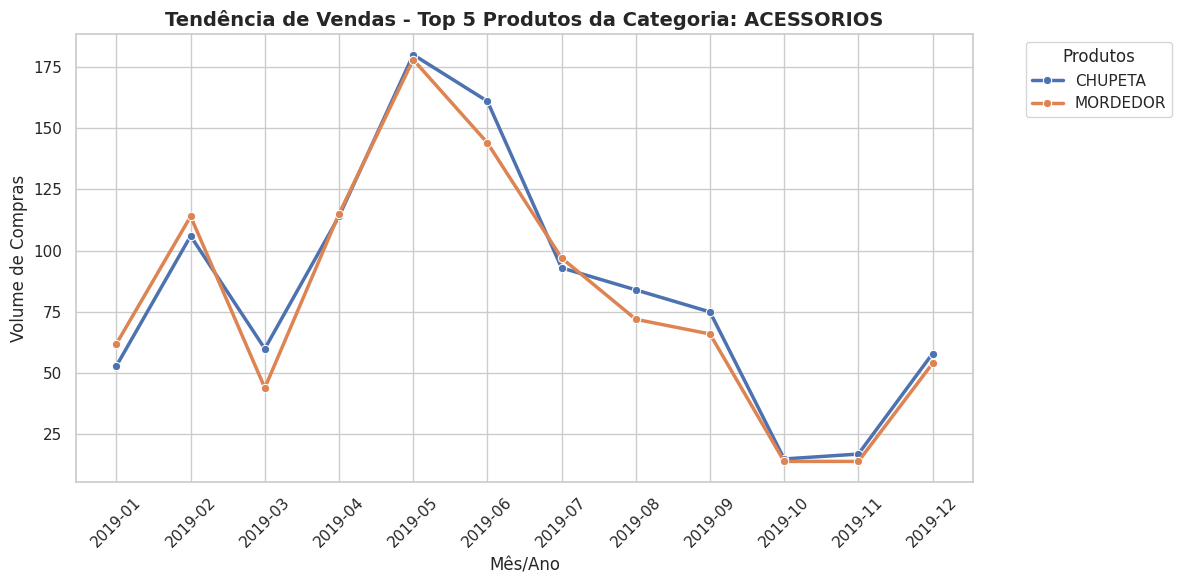

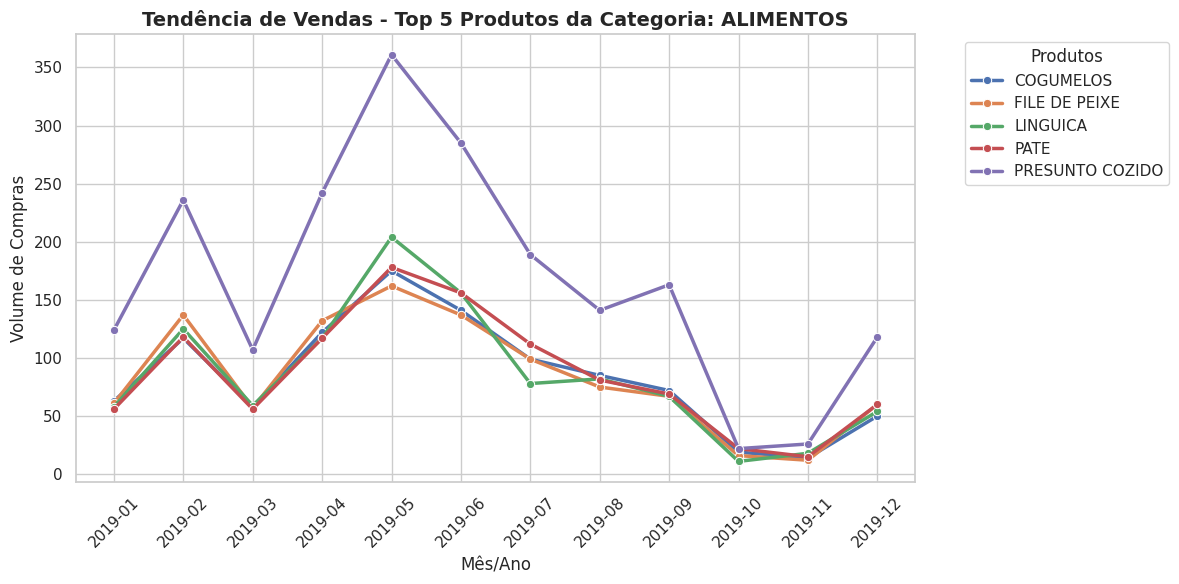

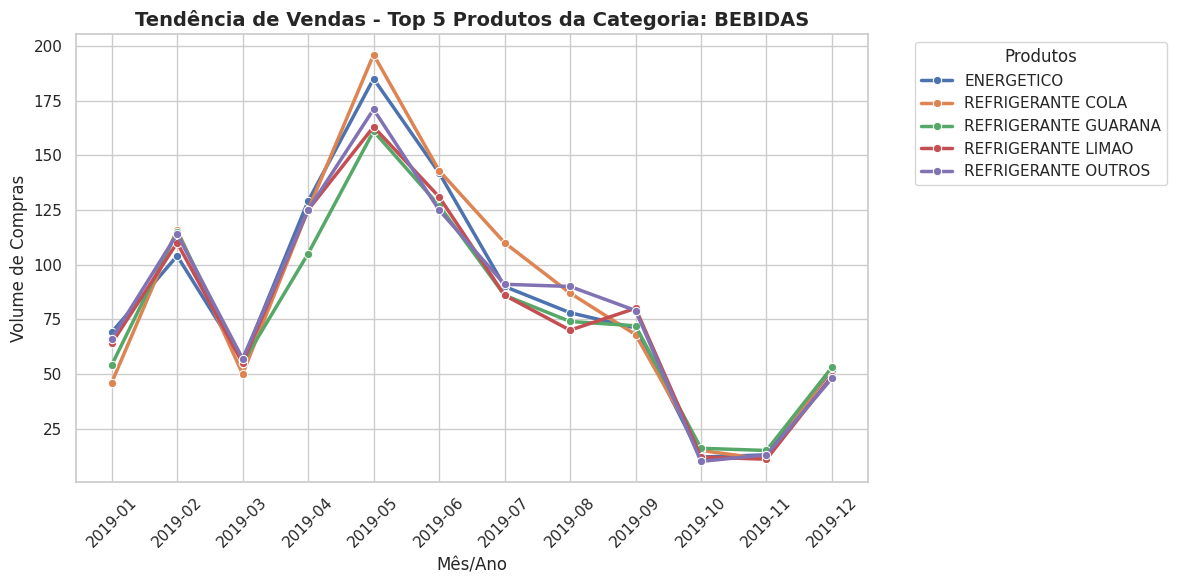

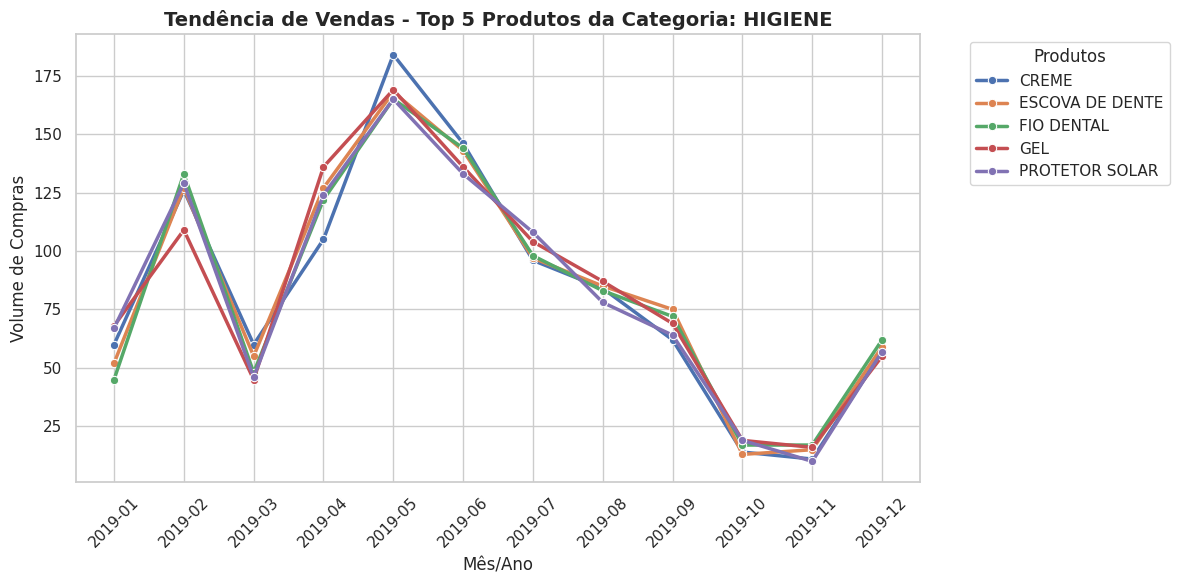

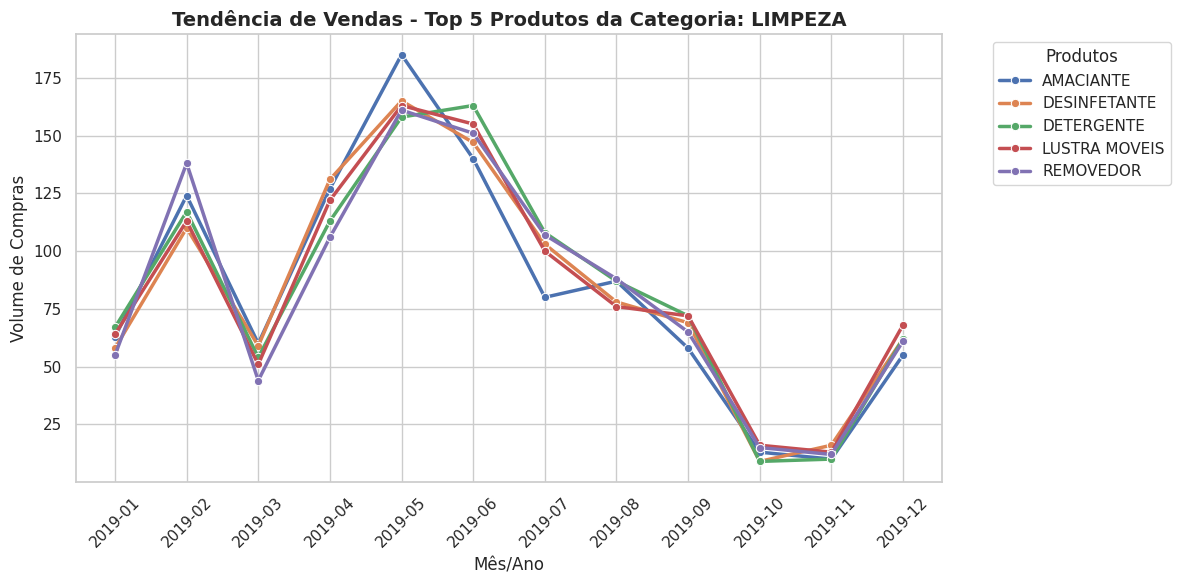

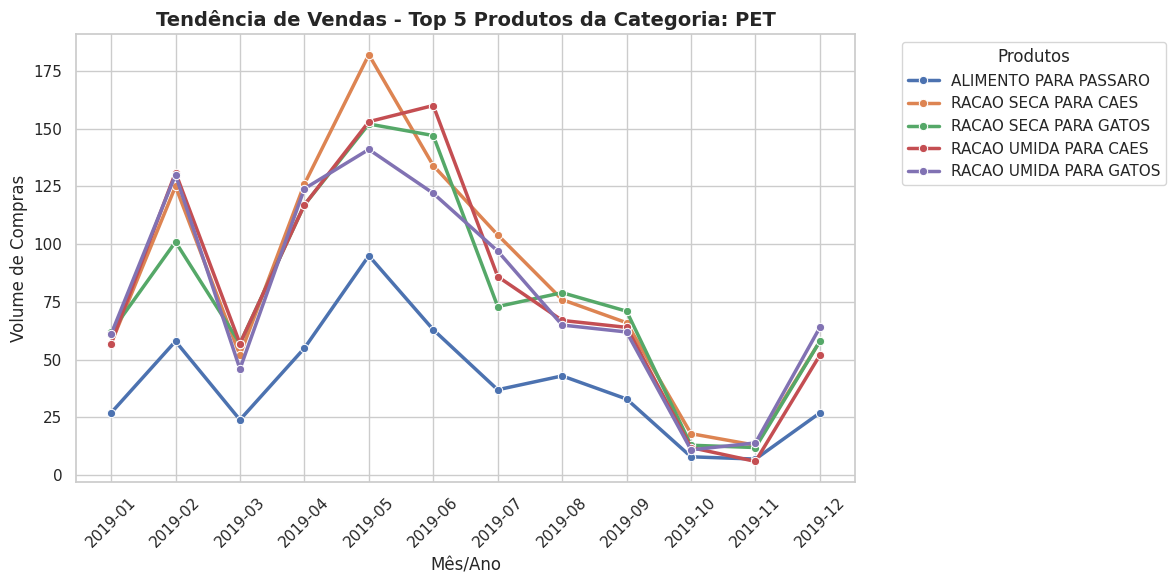

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual dos gráficos
sns.set_theme(style="whitegrid")

# Criar uma coluna de Mês/Ano para ajuste de tendência
df['MES_ANO'] = df['DATA'].dt.to_period('M').astype(str)

# Encontrar os 5 produtos mais vendidos em cada categoria
top_produtos = df.groupby(['PR_CAT', 'PR_NOME'])['CO_ID'].count().reset_index(name='TOTAL_VENDAS')
top_produtos['RANK'] = top_produtos.groupby('PR_CAT')['TOTAL_VENDAS'].rank(ascending=False, method='first')
top_5_por_cat = top_produtos[top_produtos['RANK'] <= 5]

# Filtrar a base original apenas com esses top 5 produtos de cada categoria
df_top5 = df.merge(top_5_por_cat[['PR_CAT', 'PR_NOME']], on=['PR_CAT', 'PR_NOME'])

# Agrupar por Categoria, Mês/Ano e Nome do Produto para contar as vendas no tempo
tendencia = df_top5.groupby(['PR_CAT', 'MES_ANO', 'PR_NOME'])['CO_ID'].count().reset_index(name='VENDAS')

# Gerar um gráfico de linha para cada categoria
for cat in tendencia['PR_CAT'].unique():
    if cat == '#N/D':
        continue

    subset = tendencia[tendencia['PR_CAT'] == cat]

    plt.figure(figsize=(12, 6))
    sns.lineplot(
        data=subset,
        x='MES_ANO',
        y='VENDAS',
        hue='PR_NOME',
        marker='o',
        linewidth=2.5
    )

    plt.title(f'Tendência de Vendas - Top 5 Produtos da Categoria: {cat}', fontsize=14, fontweight='bold')
    plt.xlabel('Mês/Ano', fontsize=12)
    plt.ylabel('Volume de Compras', fontsize=12)
    plt.xticks(rotation=45)

    #Adicionando a verificação para evitar o UserWarning se a legenda estiver vazia
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Produtos')

    plt.tight_layout()
    plt.show()